# Jets (Modane): 2×2 design, higher orders on/off × scalar potential on/off

| arm | label | higher orders (Scat3 Re+Im, Scat4 Mod2 Re+Im) | Scalar_morlet_gaussianK | lam (xseed, t >= 0.99) |
|---|---|---|---|---|
| full | `jets_full` | yes | yes | 1e-2 |
| noscalar | `jets_noscalar` | yes | no | 1e-2 |
| scat2_scalar | `jets_scat2_scalar` | no | yes | 1e-3 |
| scat2 | `jets_scat2` | no | no | 1e-4 |

All arms: L_6 + Scattering 1st + 2nd order, 5 seeds (500-504), same SDE set-up (`jets/launch_jet_SDE.sh`).
**Test:** statistics that only orders 3-4 can carry (time asymmetry: skewness, leverage; cross-scale C_pq; Scat4)
should be lost in `scat2*`. If they are, the higher-order potentials are what produces them.

Run on Jean Zay from `jets/` (needs `saved_results/`). Sections 1-2 compute here (moments, marginals); section 3 shows the outputs of `python jets/jets_compare.py` (4-arm run in `figures/jets_compare_scat2/`).

In [2]:
%matplotlib inline
%load_ext autoreload
%autoreload 2
import sys
from pathlib import Path
ROOT = Path.cwd()                                   # jets/
sys.path[:0] = [str(ROOT.parent / 'turbulence'), str(ROOT.parent), str(ROOT)]
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
import run_comparison as rc
import jets_compare as jc
pd.set_option('display.float_format', '{:.3f}'.format, 'display.width', 250, 'display.max_rows', 100)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

In [ ]:
ARMS = {'full': 'jets_full', 'noscalar': 'jets_noscalar',
        'scat2_scalar': 'jets_scat2_scalar', 'scat2': 'jets_scat2'}      # {display name: --label}
SEEDS = [500, 501, 502, 503, 504]
OUT = ROOT / 'figures' / 'jets_compare_scat2'             # where jets_compare.py writes (4-arm run)
runs = {}                                                  # one entry per (arm, seed)
for arm, label in ARMS.items():
    for s, cfg in jc.find_seed_configs(ROOT, label, SEEDS).items():
        if cfg is None:
            print(f'{arm} seed {s}: no saved run'); continue
        runs[f'{arm} {s}'] = rc.load_config(cfg, ROOT, label=label)
cfg0 = next(iter(runs.values()))['cfg']
x1 = jc.reference_data(cfg0)
xs = {arm: np.concatenate([r['xt'].numpy() for k, r in runs.items() if k.startswith(arm + ' ')]) for arm in ARMS}
J = int(cfg0['J'])
print('data', tuple(x1.shape), '| pooled samples', {k: v.shape for k, v in xs.items()})

## 1. Run health
Run time per seed, and how well each seed matches the statistics it imposes at the end of the run (own-scale error |target - walkers| / max_t |target|; dashed line = 1%).

In [4]:
display(pd.DataFrame({k: dict(SDE_h=r['runtime_h'], n_samples=len(r['xt'])) for k, r in runs.items()}).T)

,SDE_h,n_samples
full 500,12.964,10000.000
full 501,12.956,10000.000
full 502,12.980,10000.000
full 503,12.958,10000.000
full 504,12.953,10000.000
noscalar 500,11.972,10000.000
noscalar 501,11.977,10000.000
noscalar 502,11.972,10000.000
noscalar 503,12.041,10000.000
noscalar 504,12.004,10000.000


In [5]:
rc.plot_moment_matching(runs)

In [6]:
rc.moments_above(runs, root=ROOT)          # statistics above 1% at the end, with names

[deduplicate_filters] filters_Q: 9 -> 9 channels for channel-list potentials (dropped duplicates [], tol=1e-08)
full 500: 0/210 moments above 0.01 at the final step
[deduplicate_filters] filters_Q: 9 -> 9 channels for channel-list potentials (dropped duplicates [], tol=1e-08)
full 501: 0/210 moments above 0.01 at the final step
[deduplicate_filters] filters_Q: 9 -> 9 channels for channel-list potentials (dropped duplicates [], tol=1e-08)
full 502: 0/210 moments above 0.01 at the final step
[deduplicate_filters] filters_Q: 9 -> 9 channels for channel-list potentials (dropped duplicates [], tol=1e-08)
full 503: 0/210 moments above 0.01 at the final step
[deduplicate_filters] filters_Q: 9 -> 9 channels for channel-list potentials (dropped duplicates [], tol=1e-08)
full 504: 0/210 moments above 0.01 at the final step
[deduplicate_filters] filters_Q: 9 -> 9 channels for channel-list potentials (dropped duplicates [], tol=1e-08)
noscalar 500: 0/165 moments above 0.01 at the final step
[dedup

## 2. Wavelet marginals per channel, 4 arms (all seeds pooled)
Ratio generated / data of E|W|^2 and of the quantiles of |W| (1 = perfect, dashed), then the tails (density and survival function). Black = data. Real part first, then imaginary part. Only `full` and `scat2_scalar` impose statistics on these marginals directly (Re part, Morlet bank).

In [7]:
def plot_ratio_lines(bank, part='real', metrics=('m2', 'q0.99', 'q0.999', 'q0.9999'), n_series=10000):
    T = rc.channel_table(x1, xs, bank=bank, J=J, n_series=n_series, part=part)
    cols = rc._colors(xs)
    fig, axes = plt.subplots(1, len(metrics), figsize=(4.3 * len(metrics), 3.6), sharey=True, squeeze=False)
    for ax, m in zip(axes[0], metrics):
        for k in xs:
            ax.plot(np.arange(len(T)), T[m][k].values, marker='o', ms=3.5, lw=1.6, color=cols[k], label=k)
        ax.axhline(1.0, color='k', lw=1, ls='--'); ax.set_title(m, fontsize=10)
        ax.set_xlabel('channel (0 = finest)'); ax.grid(alpha=0.25)
    axes[0, 0].set_ylabel('generated / data'); axes[0, 0].legend(fontsize=8, frameon=False)
    fig.suptitle(f"{bank} bank (Q={rc.BANKS[bank]}), {'Re W' if part == 'real' else 'Im W'}", y=1.02)
    fig.tight_layout(); plt.show()

plot_ratio_lines('morlet')

In [8]:
rc.plot_tail_hists(x1, xs, bank='morlet', J=J, n_ch=J, n_series=10000)

### Imaginary parts

In [9]:
plot_ratio_lines('morlet', part='imag')

In [10]:
rc.plot_tail_hists(x1, xs, bank='morlet', J=J, n_ch=J, n_series=10000, part='imag')

## 3. All statistics: run vs data, and arm vs arm (from `jets/jets_compare.py`)
**(a) vs data.** Fraction of points within 2σ of the data, per statistic family and arm. σ² = data sampling noise + (seed spread of the arm)² / number of seeds.

**(b) arm vs arm, the four contrasts of the 2×2 design.** Column 1: fraction of points where A and B differ by more than 2× the seed noise of their difference. Column 2: among those, fraction where A is closer to the data (0.5 = no preference). With 5 seeds per arm, expect ~5-10% of points flagged by chance: read whole families.
Scalar effect: full vs noscalar, scat2_scalar vs scat2. Higher-order effect: full vs scat2_scalar, noscalar vs scat2. Same sign with and without the other term = the two effects don't interact.

Tables from (on JZ, after `jets_compare.py` has run once):
`python jets/jets_compare.py --plot_only --labels jets_full jets_scat2 jets_scat2_scalar jets_noscalar --names full scat2 scat2_scalar noscalar --out jets/figures/jets_compare_scat2 --pairs full:noscalar scat2_scalar:scat2 full:scat2_scalar noscalar:scat2`

run,full (with Scalar_morlet),noscalar
family,,
C_pq at tau*=20 (paper),0.507,0.509
C_pq maps (all lag pairs),0.438,0.468
Scat4 statistics,1.000,1.000
burst persistence,0.098,0.059
extremes per signal,0.417,0.333
flatness slope,0.750,0.667
increment PDFs,0.331,0.327
marginal,0.658,0.539
scaling ratio zeta4/zeta2,0.542,0.583


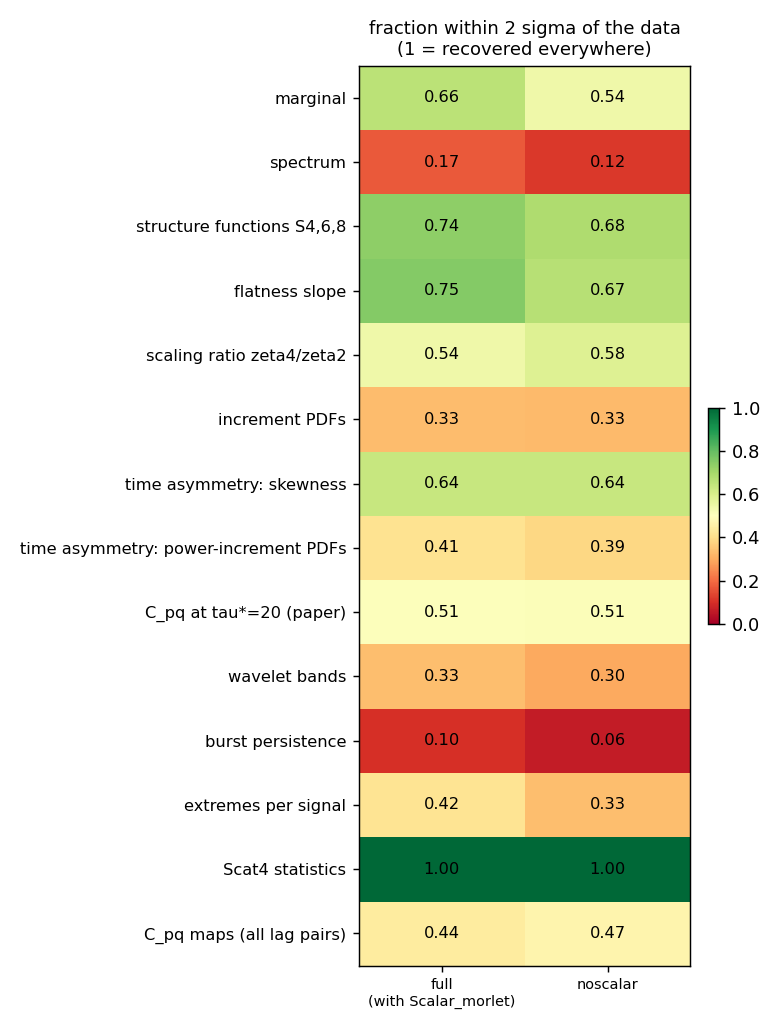

In [11]:
assert (OUT / 'summary.csv').exists(), 'run python jets/jets_compare.py first'
S = pd.read_csv(OUT / 'summary.csv')
display(S.pivot(index='family', columns='run', values='frac_within_2sigma'))
display(Image(OUT / 'summary.png'))

In [ ]:
# (b) the four contrasts of the 2x2 design: python jets/jets_compare.py --plot_only ... --pairs (see the md above)
PAIRS = [('full', 'noscalar'),          # scalar effect, with higher orders
         ('scat2_scalar', 'scat2'),     # scalar effect, without higher orders
         ('full', 'scat2_scalar'),      # higher-order effect, with scalar
         ('noscalar', 'scat2')]         # higher-order effect, without scalar
for a, b in PAIRS:
    f = OUT / f'arm_difference_{a}_vs_{b}.csv'
    if not f.exists():
        print(f'missing {f.name}: run jets_compare.py --plot_only with --pairs'); continue
    print(f'A = {a}, B = {b}')
    display(pd.read_csv(f, comment='#'))
    display(Image(OUT / f'arm_difference_{a}_vs_{b}.png'))

### Cross-scale statistics, bursts, extremes

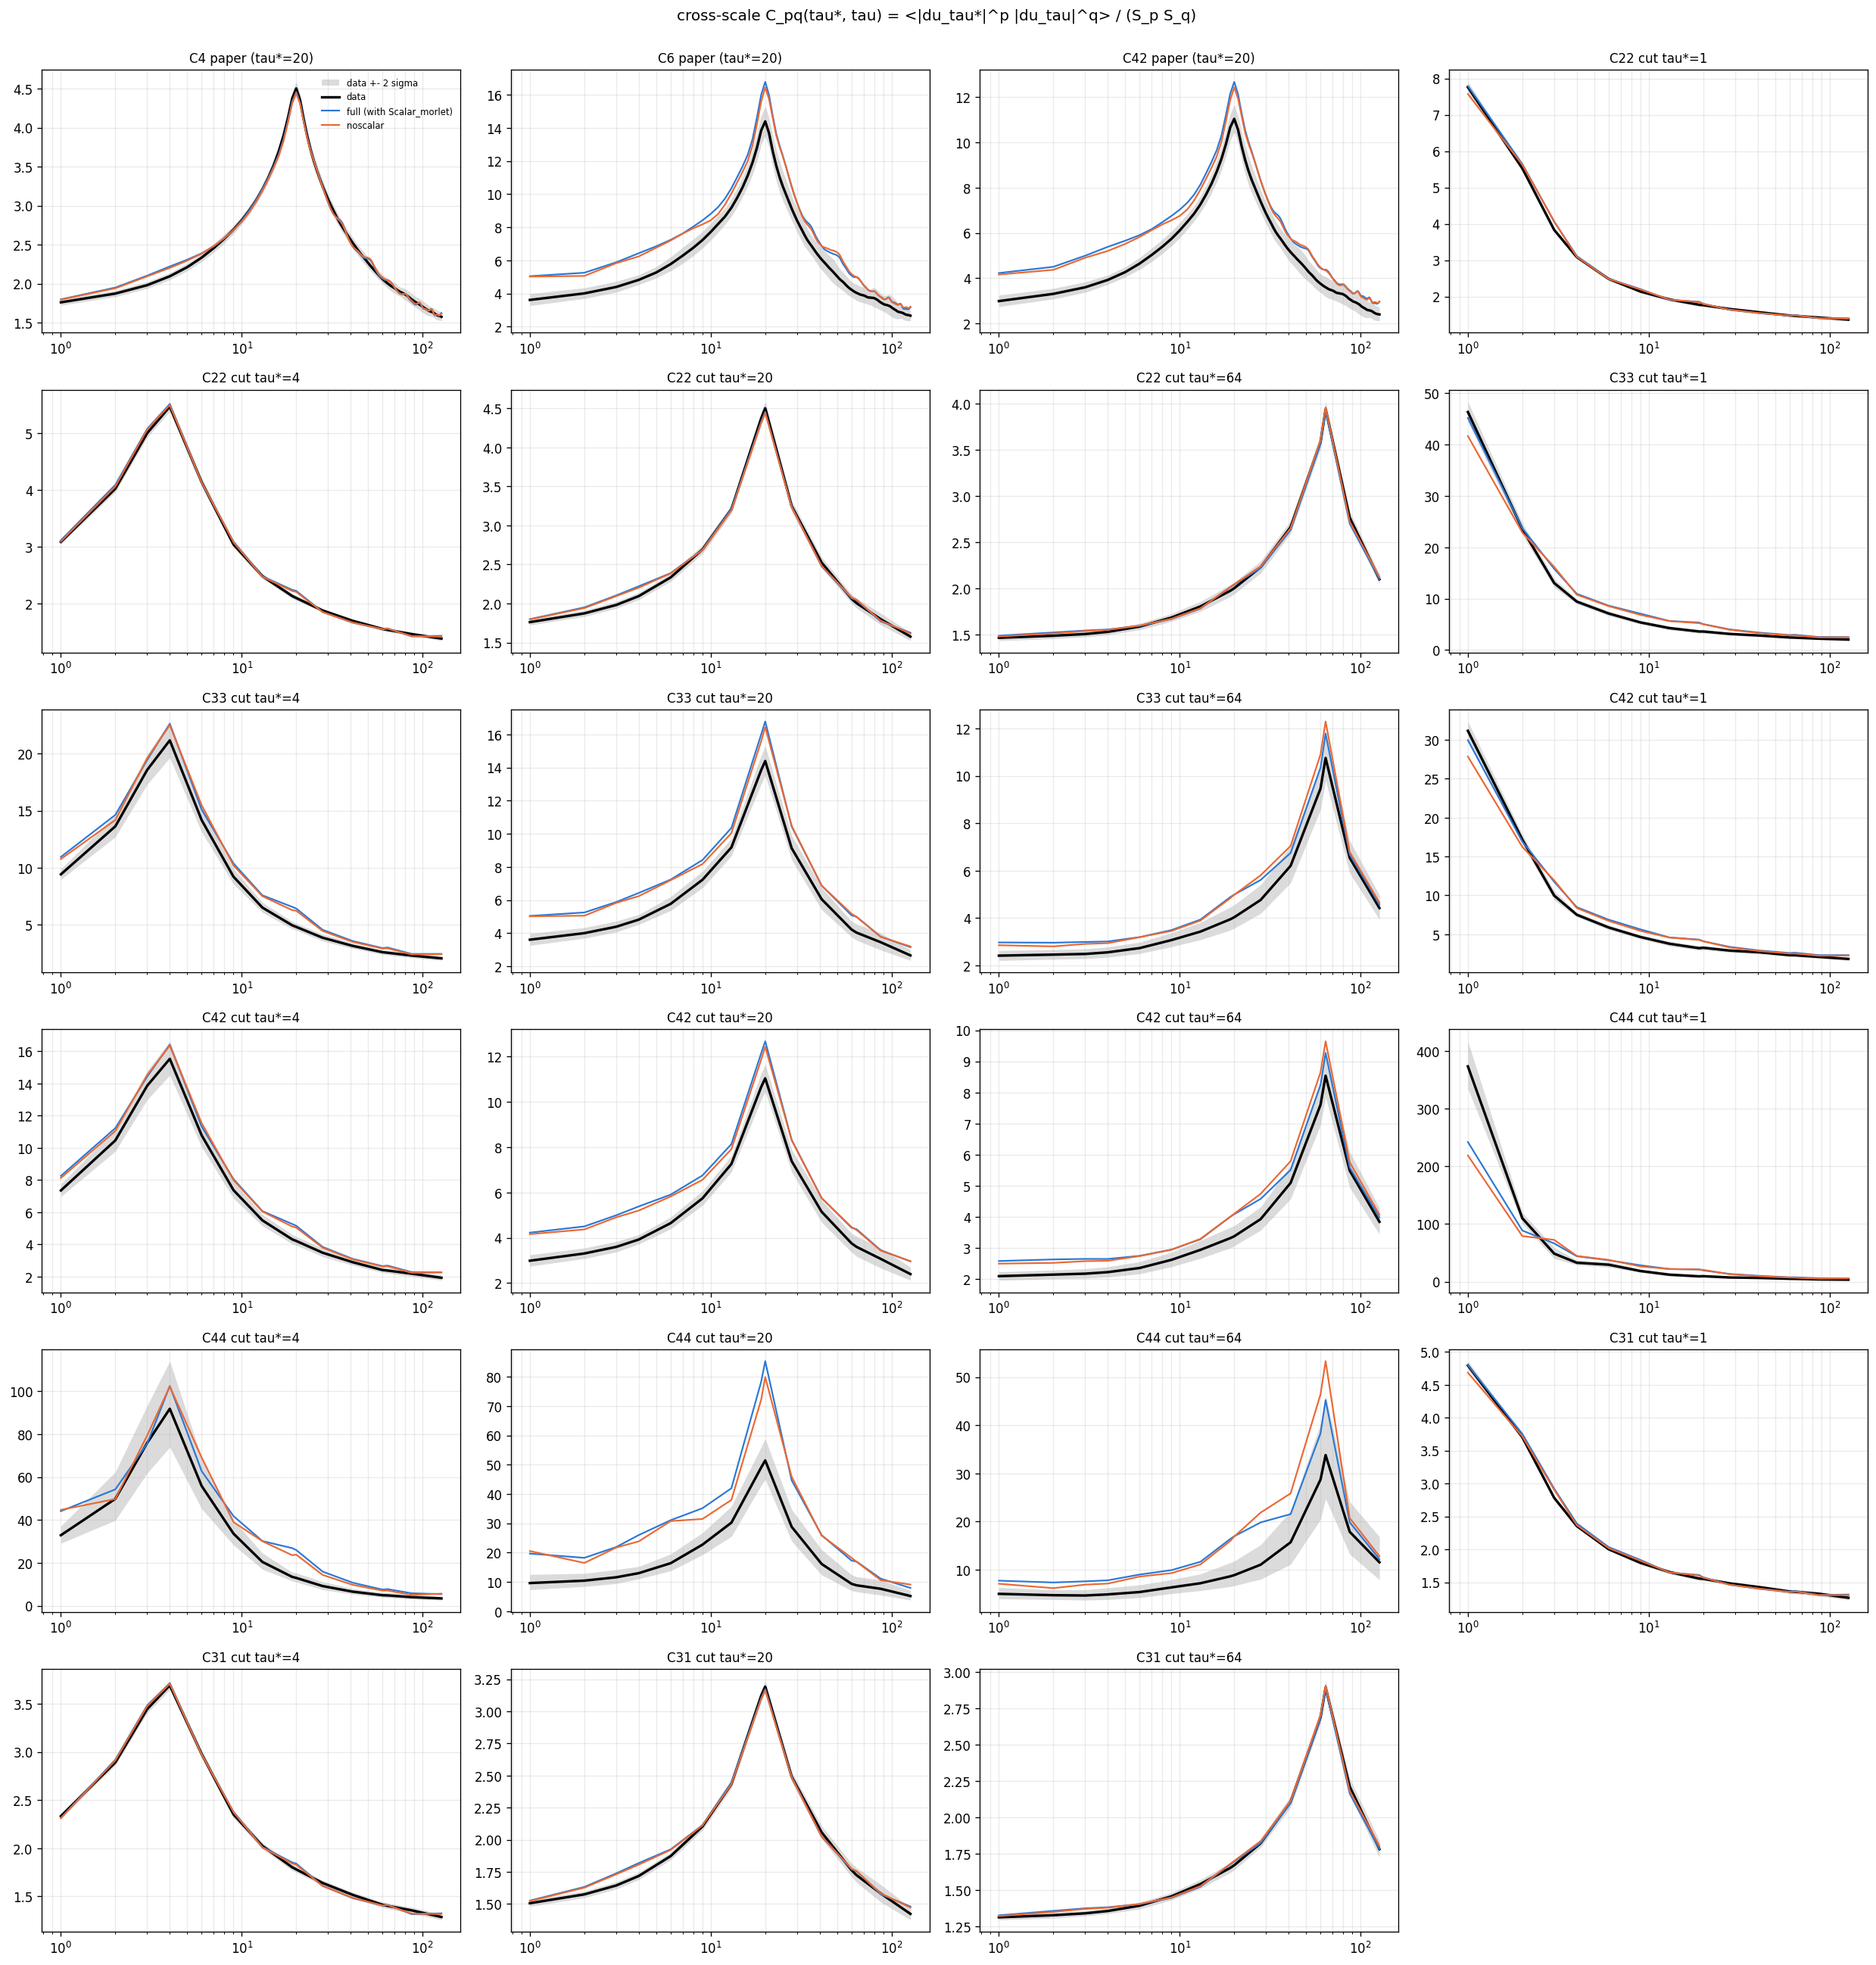

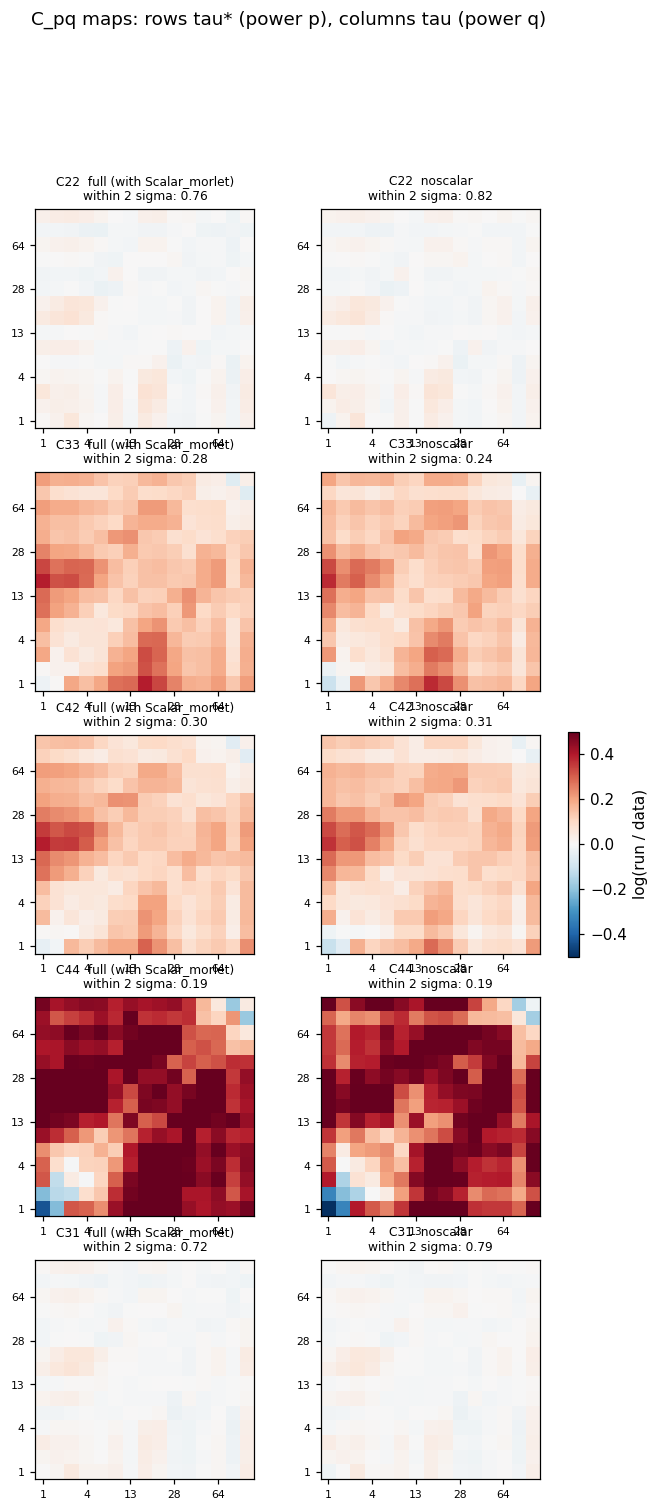

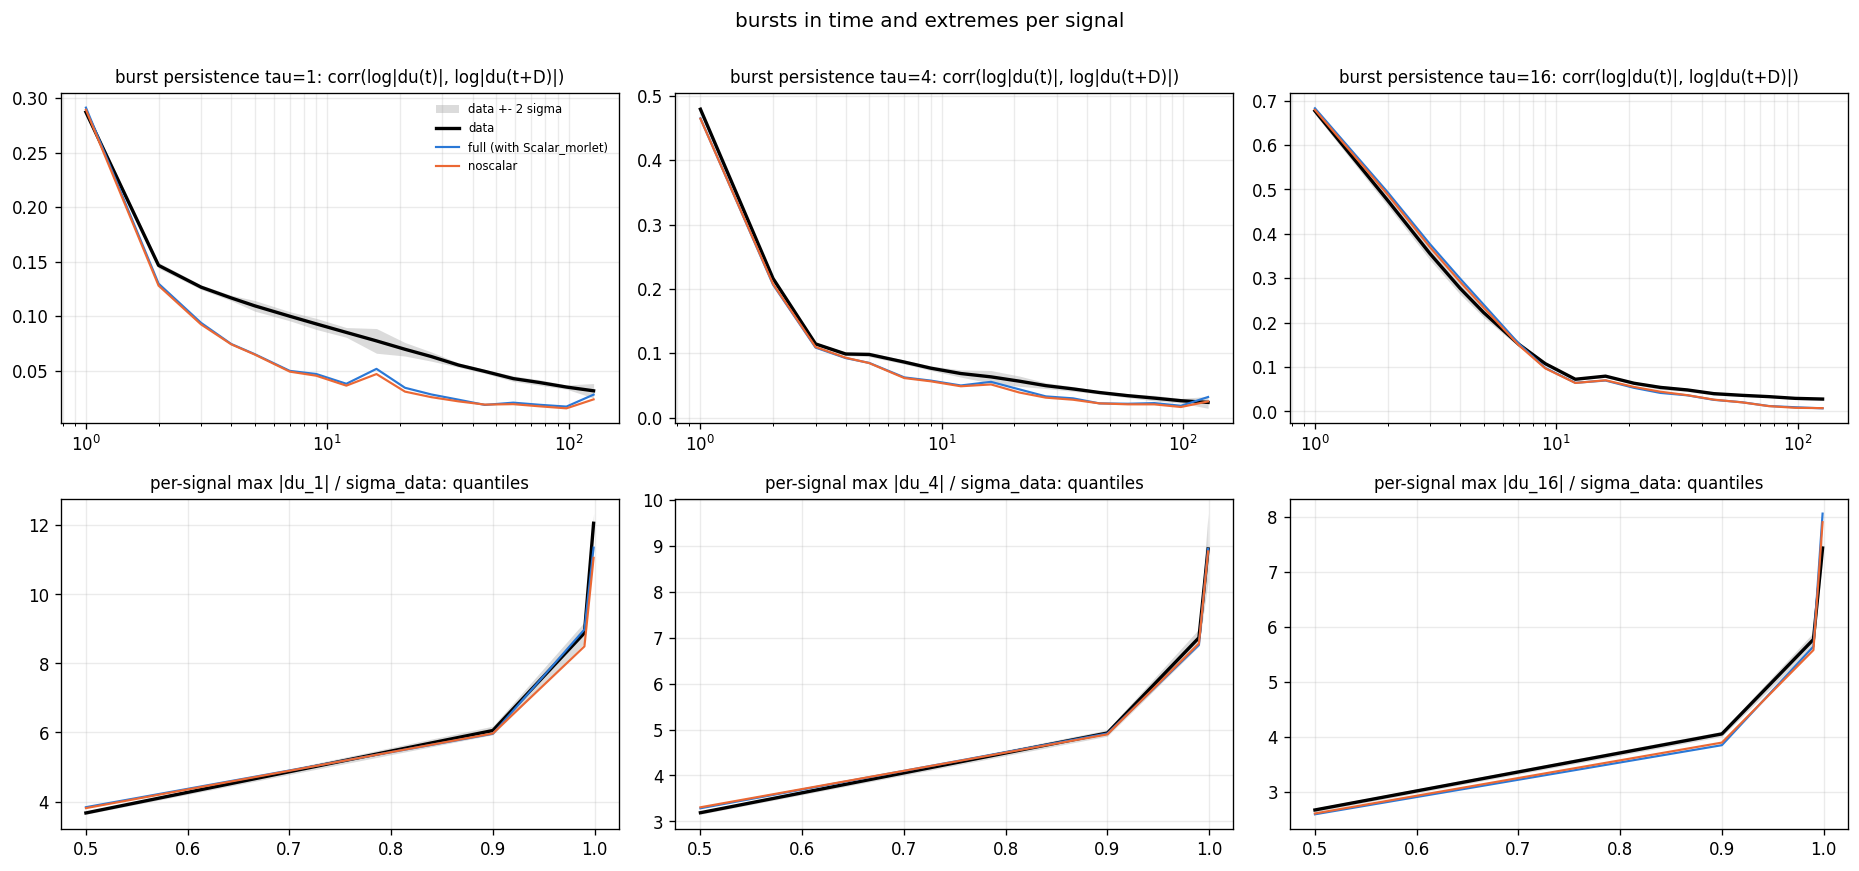

In [13]:
for f in ('cross_scale_cuts.png', 'cross_scale_maps.png', 'persistence_extremes.png'):
    display(Image(OUT / f))

### Wavelet bands, Scat4 statistics, single-scale statistics and PDFs

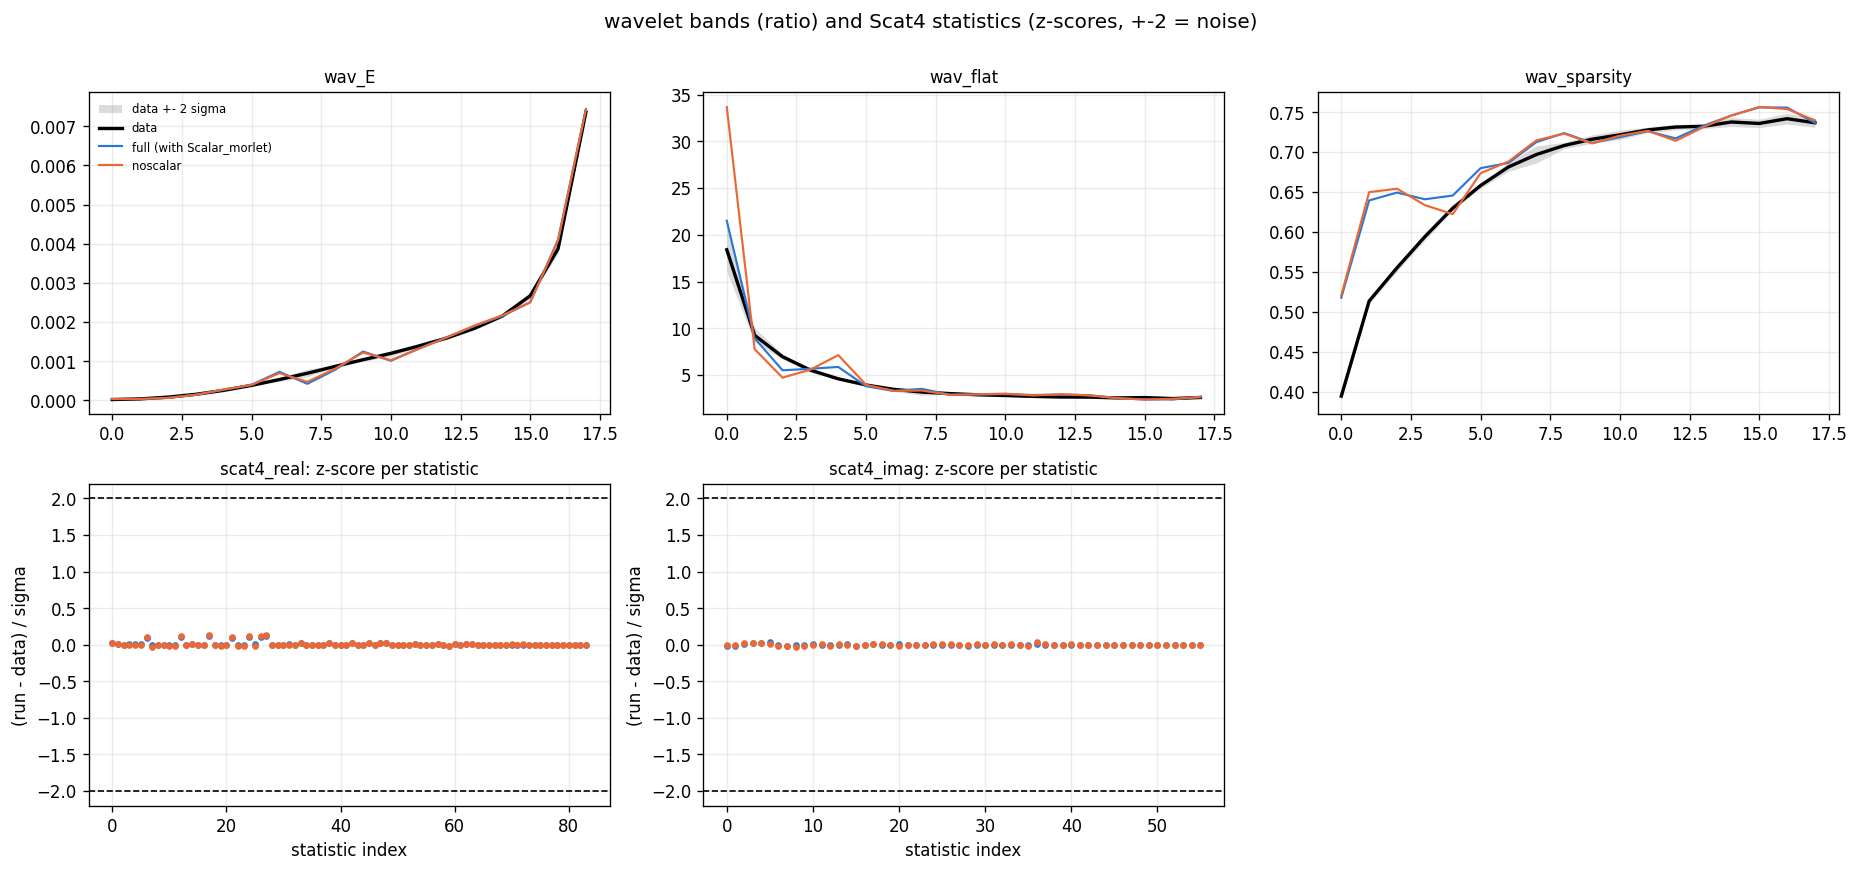

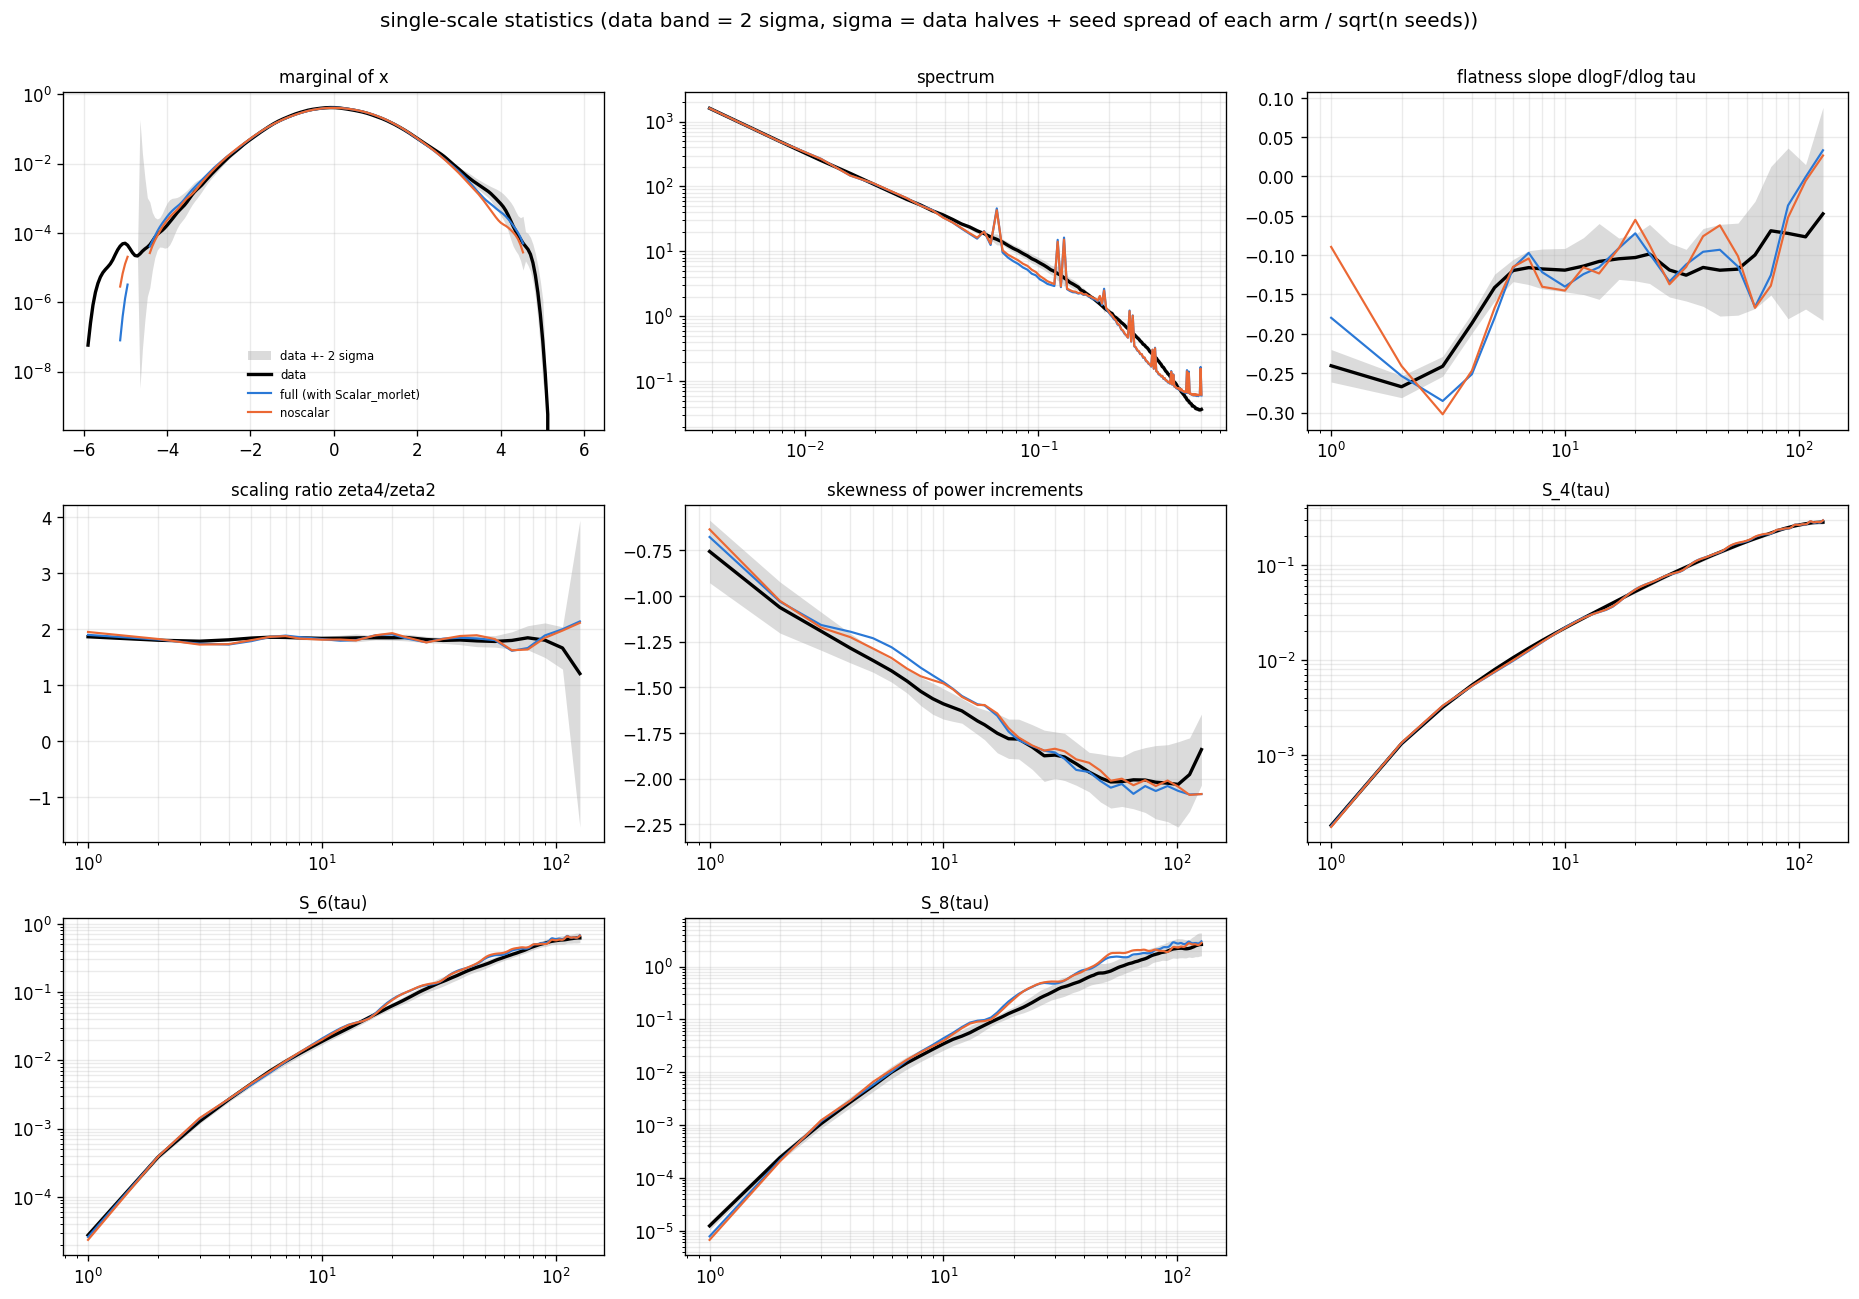

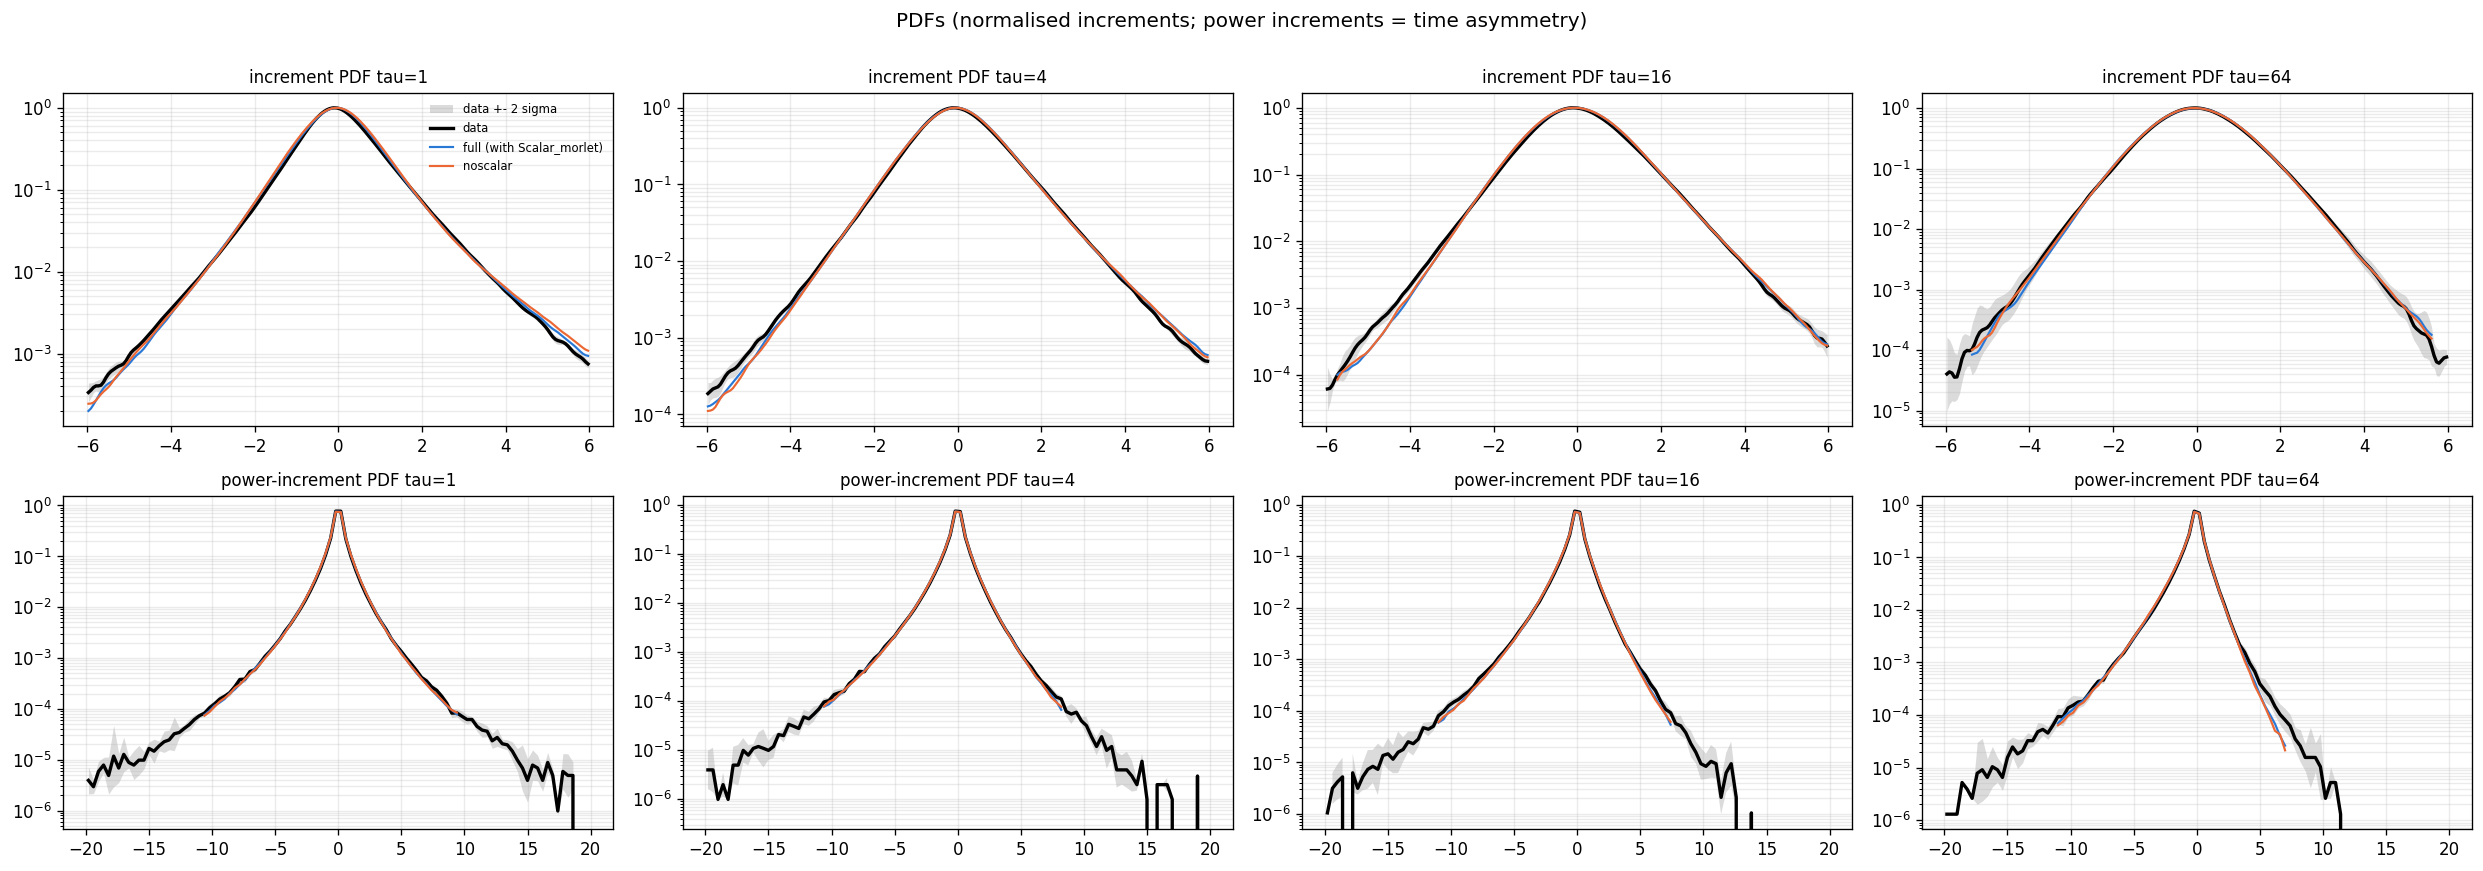

In [14]:
for f in ('wavelet_scat4.png', 'single_scale.png', 'pdfs.png'):
    display(Image(OUT / f))

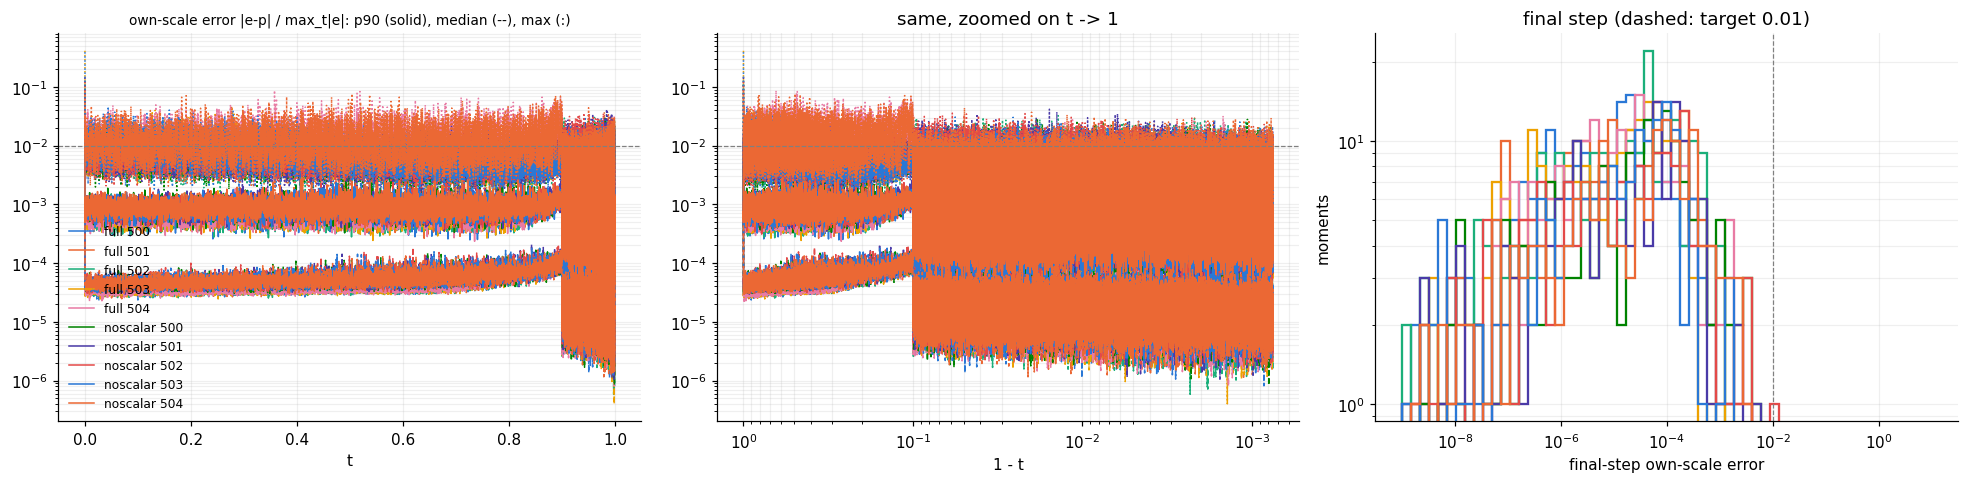

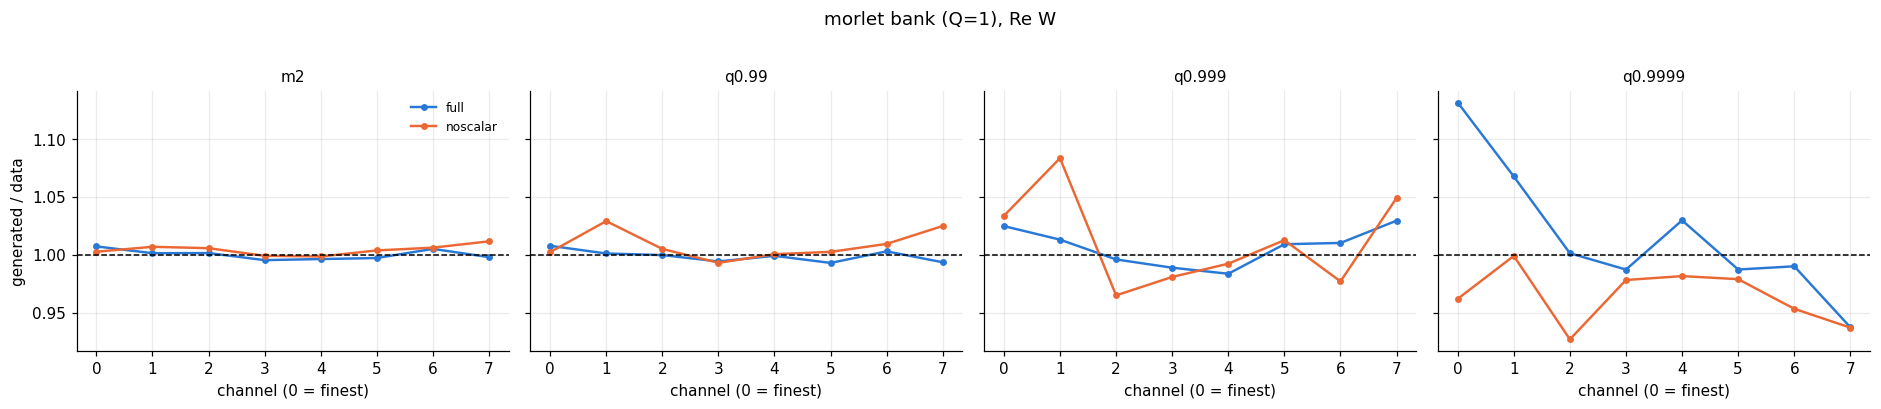

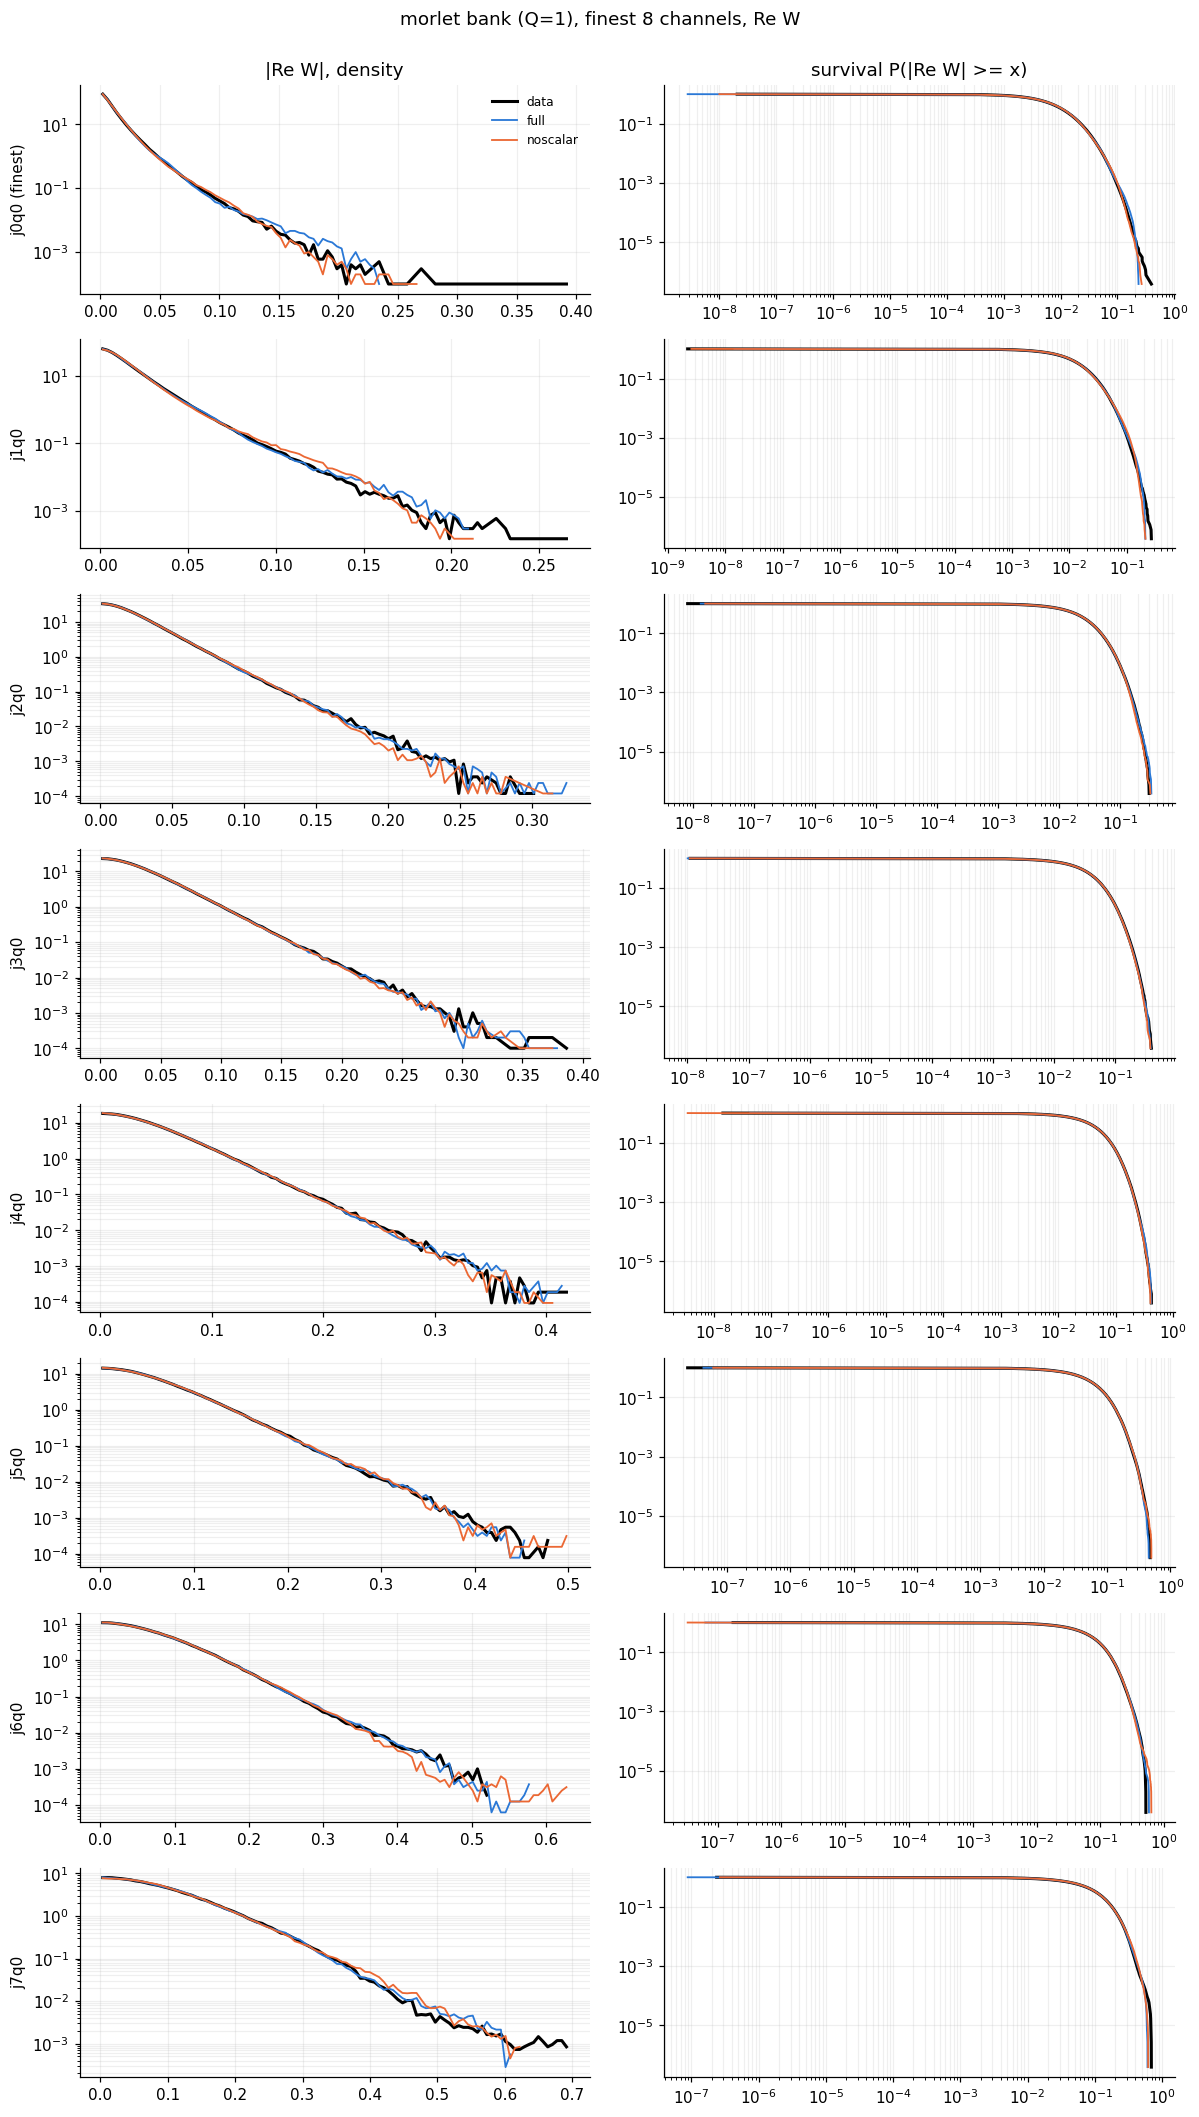

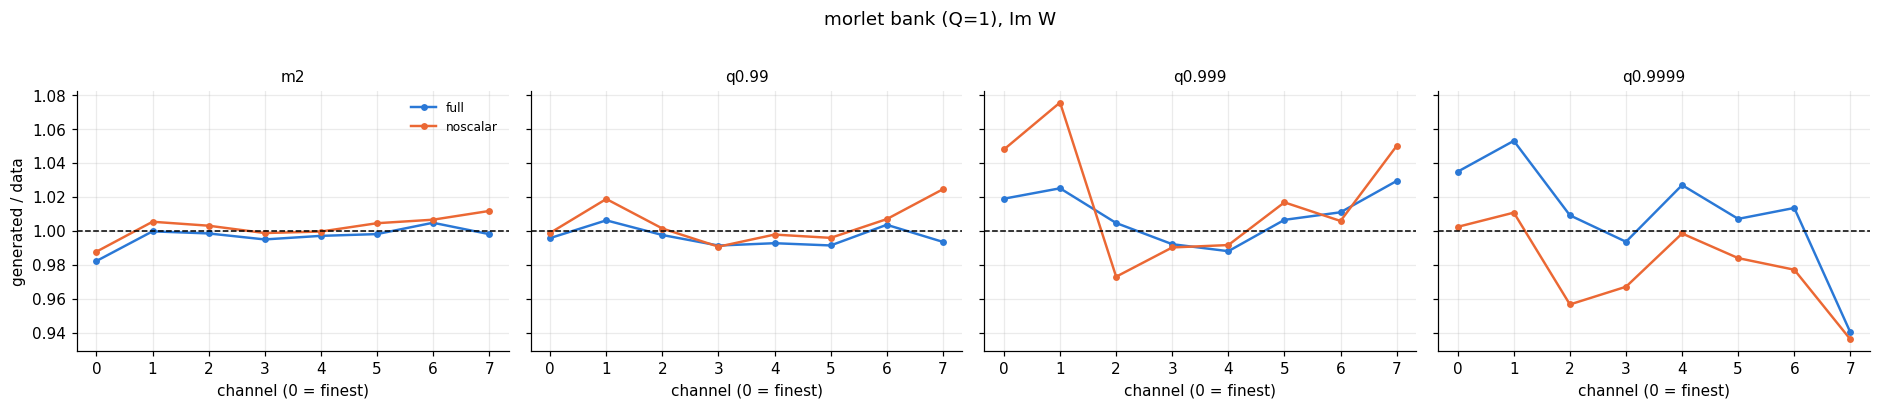

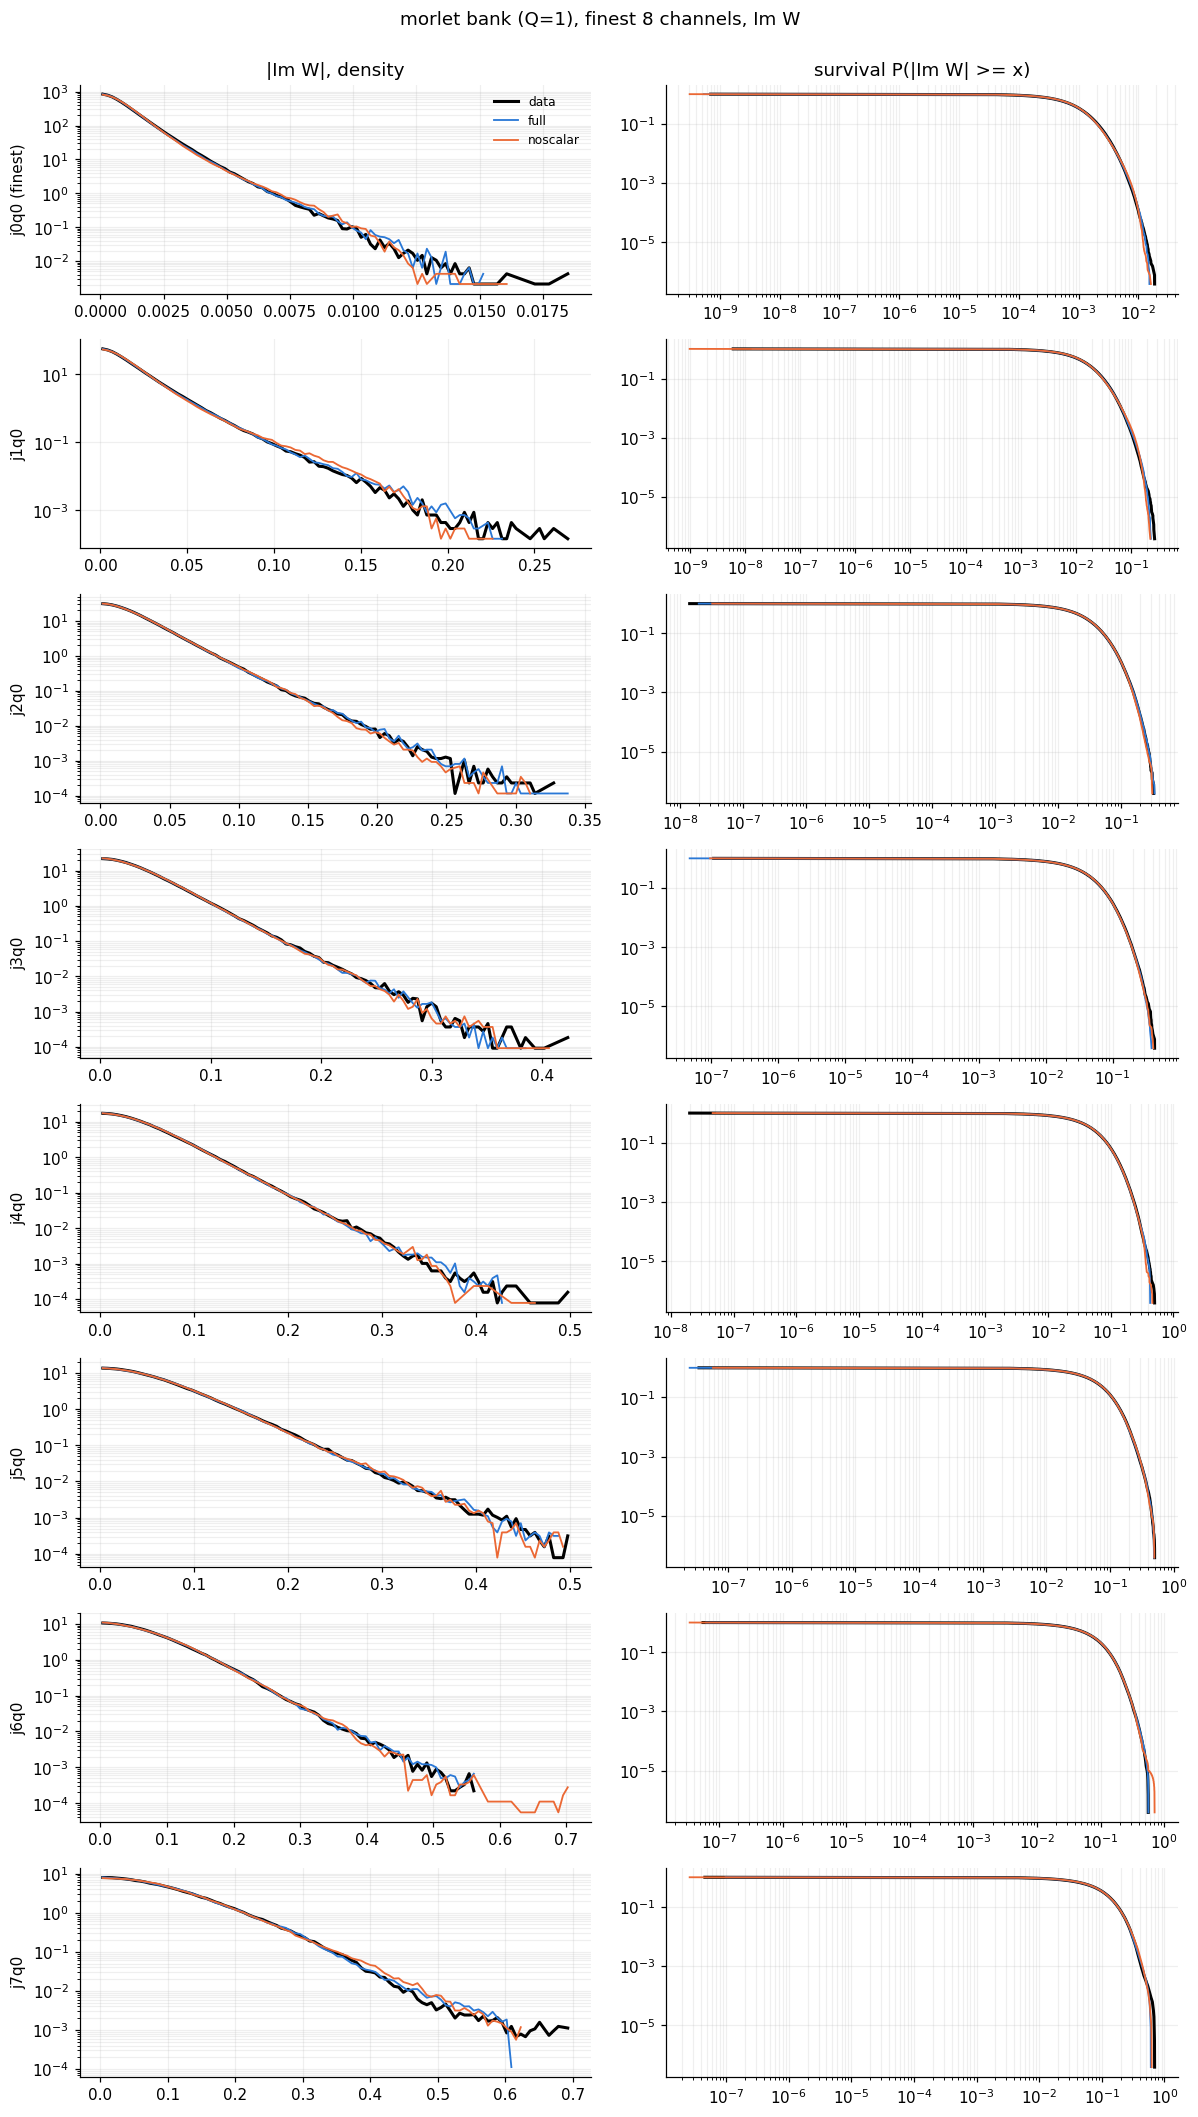

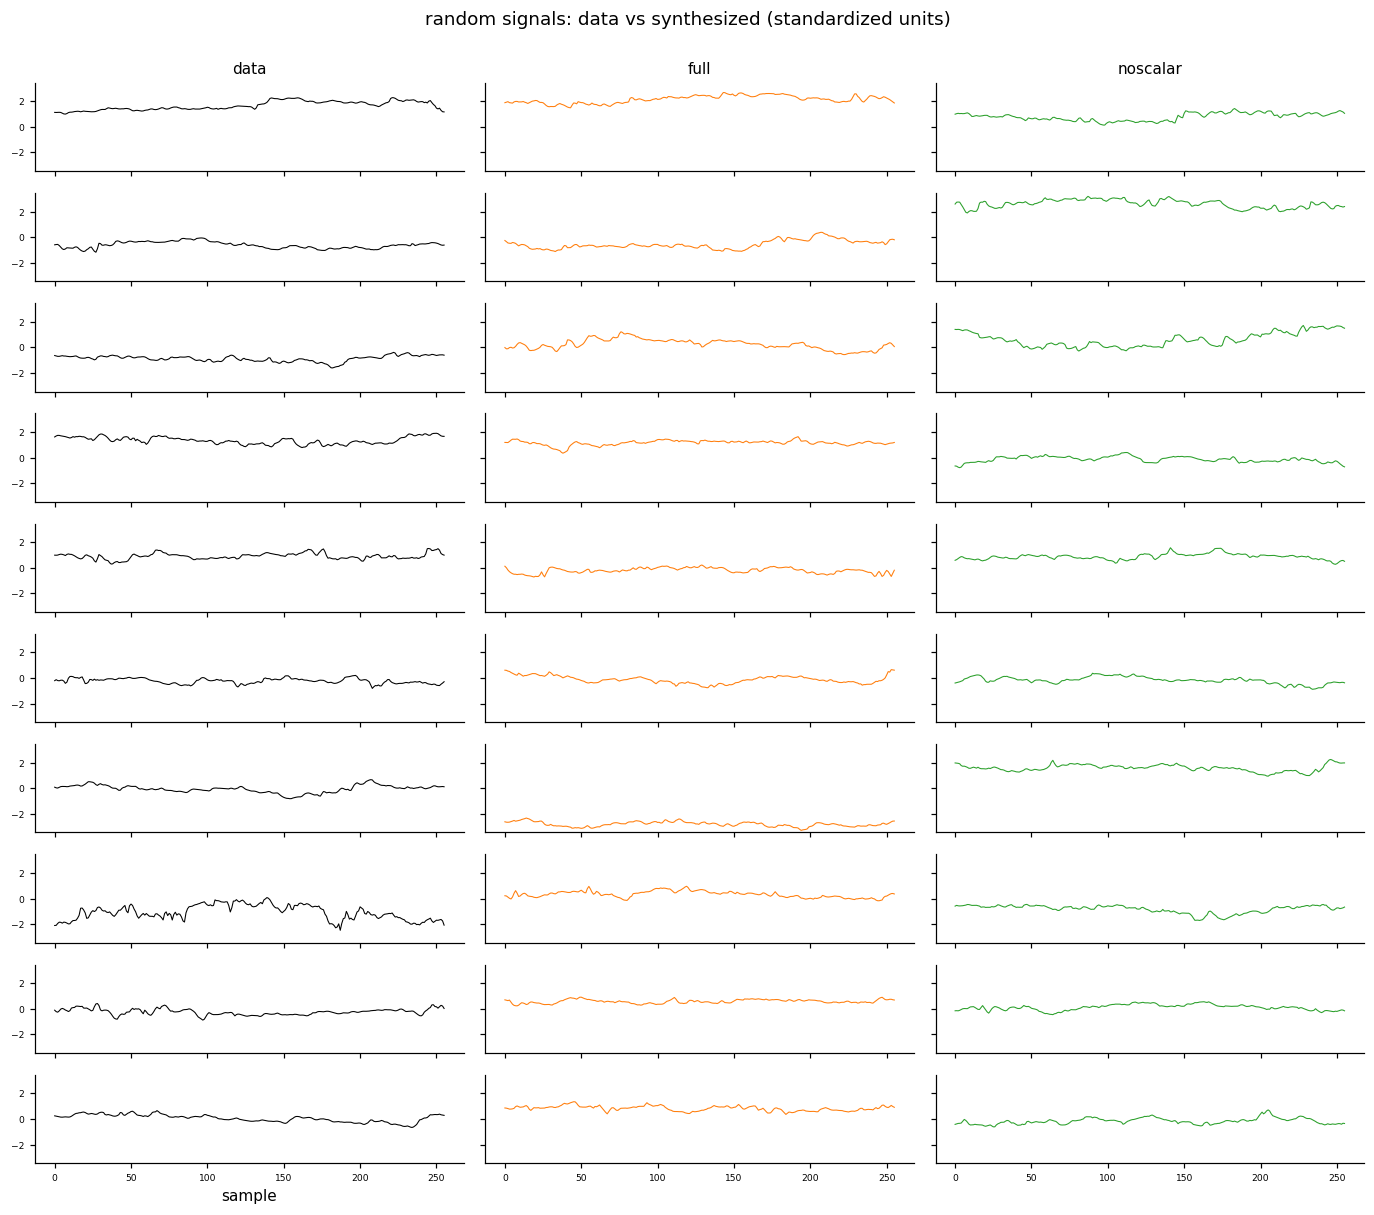

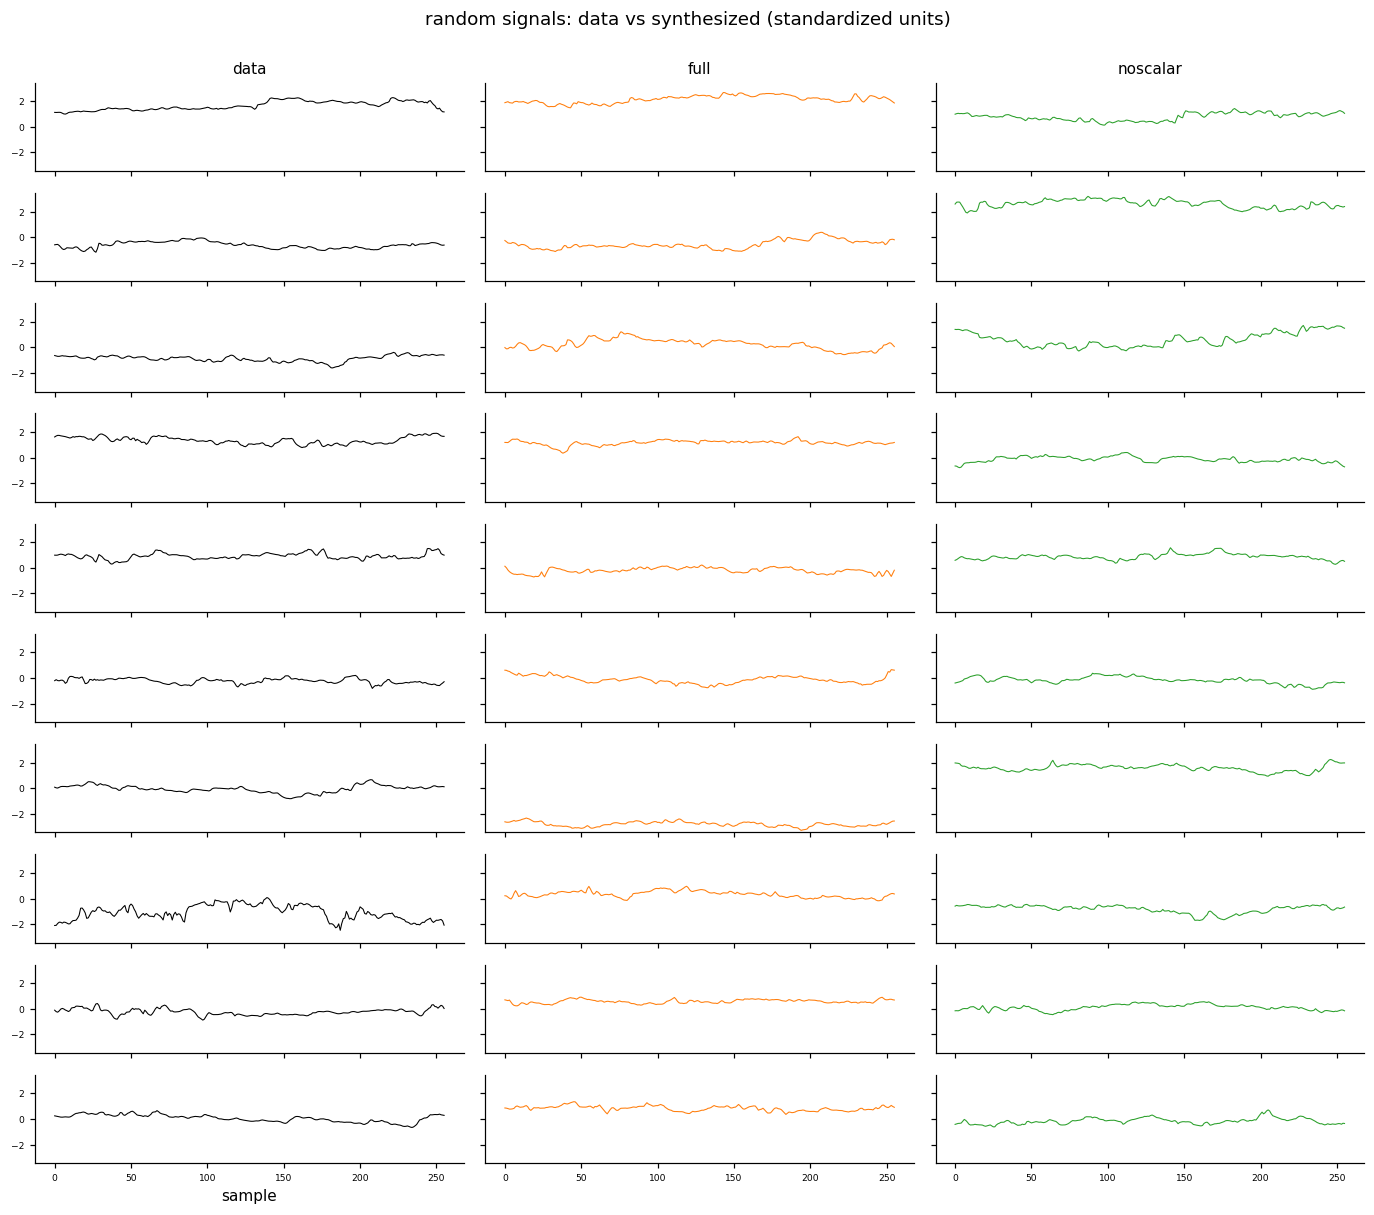

In [16]:
# 10 examples: data vs synthesized samples (one column per arm, same y-scale everywhere)
%matplotlib inline
n_ex = 10
rng = np.random.default_rng(0)
cols = {'data': x1.reshape(len(x1), -1).numpy(),
        **{arm: v.reshape(len(v), -1) for arm, v in xs.items()}}      # arms: seeds pooled
picks = {k: rng.choice(len(v), n_ex, replace=False) for k, v in cols.items()}
ylim = np.max([np.abs(v[picks[k]]).max() for k, v in cols.items()]) * 1.05
fig, axes = plt.subplots(n_ex, len(cols), figsize=(4.2 * len(cols), 1.1 * n_ex), sharex=True, sharey=True)
for j, (k, v) in enumerate(cols.items()):
    for i, idx in enumerate(picks[k]):
        axes[i, j].plot(v[idx], lw=0.7, color='k' if k == 'data' else f'C{j}')
        axes[i, j].set_ylim(-ylim, ylim)
        axes[i, j].tick_params(labelsize=6)
    axes[0, j].set_title(k, fontsize=10)
axes[-1, 0].set_xlabel('sample')
fig.suptitle('random signals: data vs synthesized (standardized units)', y=1.0)
fig.tight_layout()
plt.show()

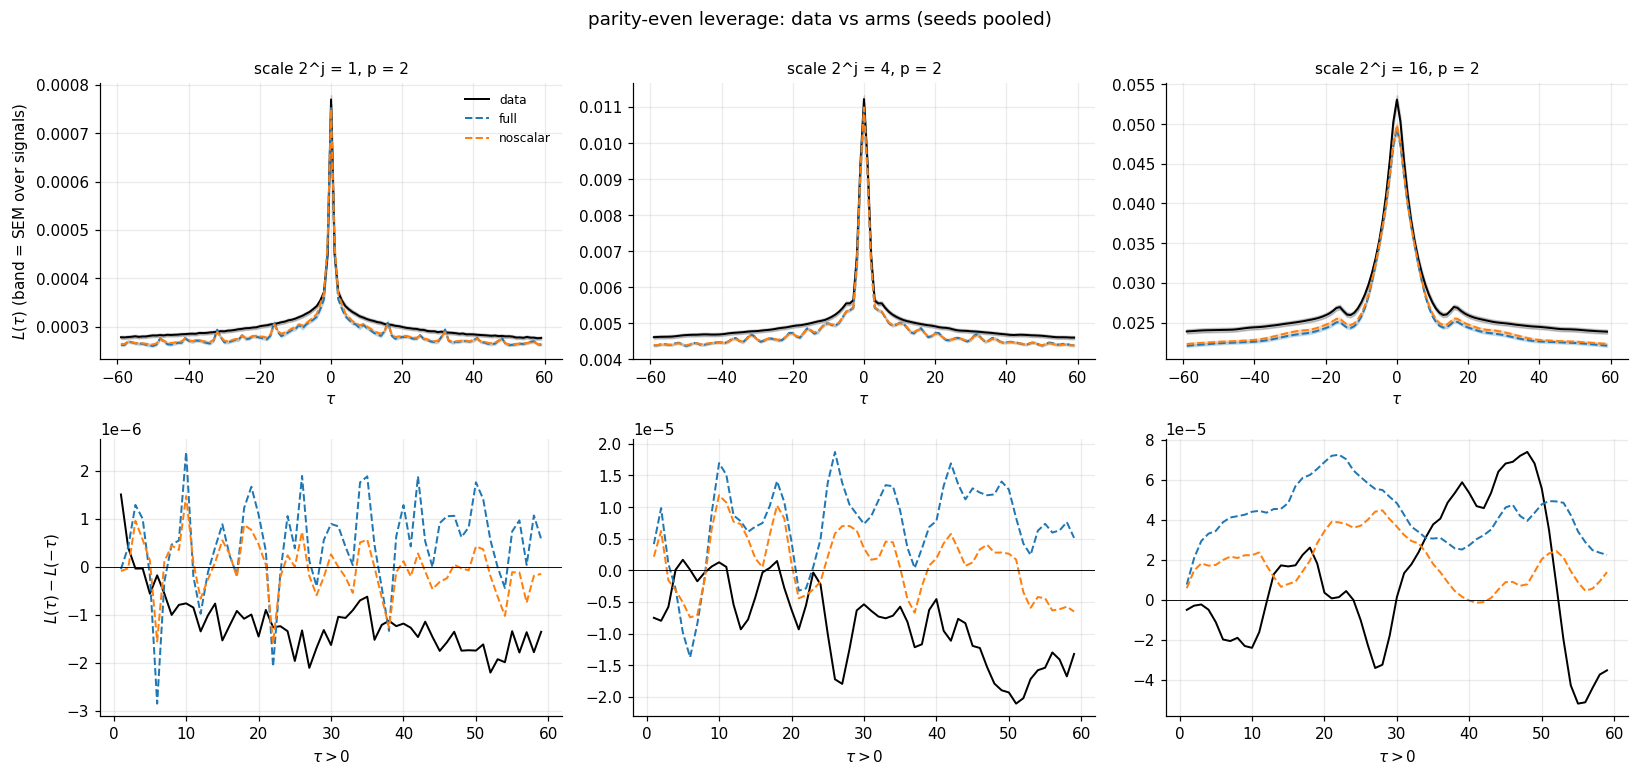

In [17]:
# parity-even leverage L(tau) = < |du(t-tau)| |du(t)|^p >, du = increment at scale 2^j; L(tau) != L(-tau) = time asymmetry
from check_moments import leverage_correlation
p, max_tau, scales = 2.0, 60, (1, 4, 16)
sets = {'data': x1.reshape(len(x1), -1).numpy(), **{arm: v.reshape(len(v), -1) for arm, v in xs.items()}}
colors = {'data': 'k', **{arm: f'C{i}' for i, arm in enumerate(xs)}}
fig, axes = plt.subplots(2, len(scales), figsize=(5 * len(scales), 7), squeeze=False)
for j, s in enumerate(scales):
    for name, v in sets.items():
        tau, L, err = leverage_correlation(v, p=p, scale=s, max_tau=max_tau)
        ls = '-' if name == 'data' else '--'
        axes[0, j].plot(tau, L, ls, color=colors[name], lw=1.3, label=name)
        axes[0, j].fill_between(tau, L - err, L + err, color=colors[name], alpha=0.2)
        pos = tau > 0                                       # asymmetry: L(tau) - L(-tau), tau > 0
        asym = L[pos] - L[np.searchsorted(tau, -tau[pos])]
        axes[1, j].plot(tau[pos], asym, ls, color=colors[name], lw=1.3, label=name)
    axes[0, j].set_title(f'scale 2^j = {s}, p = {p:g}', fontsize=10)
    axes[1, j].axhline(0, color='k', lw=0.6)
    axes[0, j].set_xlabel(r'$\tau$'); axes[1, j].set_xlabel(r'$\tau > 0$')
    for ax in axes[:, j]:
        ax.grid(alpha=0.25)
axes[0, 0].set_ylabel(r'$L(\tau)$ (band = SEM over signals)')
axes[1, 0].set_ylabel(r'$L(\tau) - L(-\tau)$')
axes[0, 0].legend(fontsize=8, frameon=False)
fig.suptitle('parity-even leverage: data vs arms (seeds pooled)', y=1.0)
fig.tight_layout()
plt.show()

In [ ]:
# signed leverage (Bouchaud, Matacz & Potters 2001, Eq. 1-2): L(tau) = < du(t-tau) du(t)^2 > / < du^2 >^2, scale 1 = the paper
#   x -> -x symmetric signal   -> L = 0 at every tau (needs an up/down asymmetry to be non-zero)
#   time-reversible signal     -> L(-tau) = -L(tau), so the even part L(tau) + L(-tau) (incl. 2 L(0)) is the time asymmetry
# 2 L(0) = 2 <du^3>/<du^2>^2: for the jet, the (negative) increment skewness. Uses sets/colors from the cell above.
from check_moments import signed_leverage_correlation
max_tau, scales = 60, (1, 4, 16)
fig, axes = plt.subplots(2, len(scales), figsize=(5 * len(scales), 7), squeeze=False)
for j, s in enumerate(scales):
    for name, v in sets.items():
        tau, L, err = signed_leverage_correlation(v, scale=s, max_tau=max_tau)
        ls = '-' if name == 'data' else '--'
        axes[0, j].plot(tau, L, ls, color=colors[name], lw=1.3, label=name)
        axes[0, j].fill_between(tau, L - err, L + err, color=colors[name], alpha=0.2)
        pos = tau >= 0                                      # even part: L(tau) + L(-tau), tau >= 0
        even = L[pos] + L[np.searchsorted(tau, -tau[pos])]
        axes[1, j].plot(tau[pos], even, ls, color=colors[name], lw=1.3, label=name)
    axes[0, j].set_title(f'scale 2^j = {s}', fontsize=10)
    for ax in axes[:, j]:
        ax.axhline(0, color='k', lw=0.6); ax.grid(alpha=0.25)
    axes[0, j].axvline(0, color='k', lw=0.6)
    axes[0, j].set_xlabel(r'$\tau$'); axes[1, j].set_xlabel(r'$\tau \geq 0$')
axes[0, 0].set_ylabel(r'$\langle \delta u(t-\tau)\,\delta u(t)^2\rangle / \langle \delta u^2\rangle^2$ (band = SEM)')
axes[1, 0].set_ylabel(r'$L(\tau) + L(-\tau)$  (0 if time-reversible)')
axes[0, 0].legend(fontsize=8, frameon=False)
fig.suptitle('signed leverage: data vs arms (seeds pooled)', y=1.0)
fig.tight_layout()
plt.show()

In [ ]:
# Zumbach moment (Morel et al. 2023, Sec. 6.2): Z(tau) = < |du_s(t-tau)|^2 Sigma_s(t) >_t, s = 2^j,
#   du_s(t) = u(t) - u(t-s) (coarse move), Sigma_s(t) = mean of the s squared 1-step increments in the SAME window (aligned:
#   the paper's literal window is one sample earlier, which fakes an asymmetry on a reversible signal; zumbach_moment docstring)
#   time-reversible -> Z(-tau) = Z(tau); bottom row = cumulative asymmetry A(t) = sum_{v=0..t} [Z(v) - Z(-v)] (paper Fig. 8)
# 2^j = 1 is left out: there Z(tau) is the autocorrelation of du^2, exactly symmetric for any signal.
# Each set divided by its own <|du_s|^2> <|du_1|^2> (Z = 1: coarse move and volatility independent). Uses sets/colors from above.
from check_moments import zumbach_moment
scales = (4, 16, 64)
fig, axes = plt.subplots(2, len(scales), figsize=(5 * len(scales), 7), squeeze=False)
for j, s in enumerate(scales):
    for name, v in sets.items():
        tau, Z, eZ, t, A, eA = zumbach_moment(v, scale=s, max_tau=max(60, 2 * s))
        norm = np.mean((v[:, s:] - v[:, :-s]) ** 2) * np.mean(np.diff(v, axis=-1) ** 2)
        ls = '-' if name == 'data' else '--'
        for ax, x_, y, e in ((axes[0, j], tau, Z, eZ), (axes[1, j], t, A, eA)):
            ax.plot(x_, y / norm, ls, color=colors[name], lw=1.3, label=name)
            ax.fill_between(x_, (y - e) / norm, (y + e) / norm, color=colors[name], alpha=0.2)
    axes[0, j].set_title(f'scale 2^j = {s}', fontsize=10)
    for ax in axes[:, j]:
        ax.axhline(0 if ax is axes[1, j] else 1, color='k', lw=0.6); ax.grid(alpha=0.25)
    axes[0, j].axvline(0, color='k', lw=0.6)
    axes[0, j].set_xlabel(r'$\tau$'); axes[1, j].set_xlabel(r'$t$')
axes[0, 0].set_ylabel(r'$Z(\tau) / \langle|\delta_j u|^2\rangle\langle|\delta_0 u|^2\rangle$ (band = SEM)')
axes[1, 0].set_ylabel(r'$\sum_{v=0}^{t} [Z(v) - Z(-v)]$  (0 if time-reversible)')
axes[0, 0].legend(fontsize=8, frameon=False)
fig.suptitle('Zumbach moment: data vs arms (seeds pooled)', y=1.0)
fig.tight_layout()
plt.show()

In [ ]:
# skewness of increments W(tau) vs tau, two definitions (check_moments._increment):
#   power: W = (v(t+tau) - v(t)) v(t) = exact - (1/2) dv^2  -> NOT 0 for a reversible signal (the -dv^2/2 term skews it
#          negative; Gaussian AR(1) check 10-29: -0.95 .. -2.7). Data vs model is still a fair comparison.
#   exact: W = (v(t+tau)^2 - v(t)^2) / 2 (energy increment, flight-crash) -> 0 at every tau for a reversible signal.
import torch
from check_moments import skewness_vs_tau, logspaced_taus
T = x1.shape[-1]
taus = logspaced_taus(T, num_points=45)[:-1]                     # positive lags, as plot_skewness_comparison
as3d = lambda v: torch.as_tensor(np.asarray(v, dtype=np.float32)).reshape(len(v), 1, -1)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, mode in zip(axes, ('exact', 'power')):
    _, s = skewness_vs_tau(as3d(x1), taus, mode=mode)
    ax.plot(taus, s, 'k-o', ms=3, lw=1.6, label='data', zorder=3)
    for i, arm in enumerate(ARMS):
        for j, (k, r) in enumerate((k, r) for k, r in runs.items() if k.startswith(arm + ' ')):
            _, s = skewness_vs_tau(as3d(r['xt']), taus, mode=mode)
            ax.plot(taus, s, '--', color=f'C{i}', lw=1, alpha=0.8, label=f'{arm} (1 line per seed)' if j == 0 else None)
    ax.axhline(0, color='k', lw=0.5)
    ax.set_xscale('log'); ax.set_xlabel(r'$\tau$ (samples)'); ax.grid(alpha=0.25)
    ax.set_title(f'{mode} increments' + (' (0 = time-reversible)' if mode == 'exact' else ' (reversible != 0)'), fontsize=10)
axes[0].set_ylabel('skewness of $W(\\tau)$'); axes[0].legend(fontsize=8, frameon=False)
fig.suptitle('time asymmetry: data vs synthesized', y=1.0)
fig.tight_layout()
plt.show()

!!!!! test: remove orders 3 and 4 aand check leverage etc 
------> if we lose the statistics which we expect to recover only by having order 3 and 4 in the model, then the model is correct. 
find the correct interpretation of log p to mtch this finding. 